# Sondage du retriever

Six mesures sur la collection `rag_corpus`, telle qu'indexée par `ingest.py` (chunks de 180 tokens, overlap de 40). Les chiffres rédigés en clair dans ce notebook valent pour cet état de l'index : 123 chunks, 16 documents.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from embeddings import MODEL_NAME
from retriever import collection, search

K_MAX = 10                       # profondeur de recherche utilisée dans tout le sondage
N_CHUNKS = collection.count()

# Couleurs des figures
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"

print(f"{MODEL_NAME} — {N_CHUNKS} chunks")

intfloat/multilingual-e5-base — 123 chunks


## Étape 1 · Le jeu de sondage

Douze questions : huit répondables, deux limites (q09 croise deux documents, q10 n'a qu'une réponse partielle) et deux pièges. `gold` liste les ids des chunks qui, lus seuls, contiennent la réponse ; un piège a `gold: []`.

In [19]:
# gold établi sur la collection courante : chunks de 180 tokens, overlap 40
PROBES = [
    {"id": "q01", "question": "Quel est le délai de rétractation pour un achat en ligne ?",
     "gold": ["5e780c88572ced23", "bb8e74bb95c297ae"], "kind": "answerable"},   # 14 jours — vente-a-distance-retractation.md #0, #1
    {"id": "q02", "question": "Peut-on se rétracter d'un achat fait en magasin ?",
     "gold": ["667c04be88c3a509", "0f3d465e265f1f09"], "kind": "answerable"},   # non, geste commercial — achat-en-magasin.txt #0, #1
    {"id": "q03", "question": "Qui paie les frais de retour quand on se rétracte d'un achat à distance ?",
     "gold": ["59b874b67076d75e", "9a48845ccc66cb70"], "kind": "answerable"},   # le consommateur, sauf deux cas — retours-et-remboursements.md #0, #1
    {"id": "q04", "question": "Le vendeur ne m'a indiqué aucune date de livraison : de combien de temps dispose-t-il au maximum pour me livrer ?",
     "gold": ["0972407cc72453b5"], "kind": "answerable"},                       # 30 jours — livraison-et-delais.txt #0
    {"id": "q05", "question": "Quels jours et à quelles heures un professionnel a-t-il le droit de m'appeler pour du démarchage téléphonique ?",
     "gold": ["66b170acf6cb212e"], "kind": "answerable"},                       # lun-ven 10h-13h / 14h-20h — demarchage-et-vente-hors-etablissement.txt #4
    {"id": "q06", "question": "Mon avion est arrivé avec quatre heures de retard : à quelle indemnisation ai-je droit ?",
     "gold": ["a4b69750d883b6e4"], "kind": "answerable"},                       # 250 / 400 / 600 euros selon la distance — voyages-et-transports.txt #8
    {"id": "q07", "question": "J'ai acheté un téléphone reconditionné chez un professionnel : pendant combien de temps un défaut est-il présumé avoir existé dès l'achat ?",
     "gold": ["2fbee376fb1ef47e"], "kind": "answerable"},                       # 12 mois (24 pour du neuf) — reparation-et-durabilite.md #3
    {"id": "q08", "question": "J'ai versé une avance en commandant un canapé et je ne veux plus l'acheter : est-ce que je perds cette somme ?",
     "gold": ["2db791b5783b9b63", "6d358451318d9bd6"], "kind": "answerable"},   # arrhes par défaut, donc perdues — paiement-arrhes-et-acomptes.txt #0, #1
    {"id": "q09", "question": "Un article acheté en soldes avec la mention « ni repris ni échangé » tombe en panne au bout de six mois : le vendeur peut-il refuser de le reprendre, et combien de temps après l'achat la garantie de conformité me couvre-t-elle ?",
     "gold": ["53353883912af98b", "2ab7c37f8c4b4e5b"], "kind": "limite"},       # mention sans effet si défaut — soldes-et-reductions-de-prix.txt #3 ; 2 ans — garanties-legales.md #0
    {"id": "q10", "question": "Quelles sont les dates exactes des soldes d'hiver cette année ?",
     "gold": ["62852d845da6cdee"], "kind": "limite"},                           # partiel : début en janvier, 4 semaines, dates fixées par arrêté — soldes-et-reductions-de-prix.txt #0
    {"id": "q11", "question": "Quel est le délai de rétractation après la signature d'un compromis de vente pour un appartement ?",
     "gold": [], "kind": "trap"},                                               # immobilier absent du corpus, vocabulaire très proche
    {"id": "q12", "question": "Combien de jours de congés payés un salarié acquiert-il par mois travaillé ?",
     "gold": [], "kind": "trap"},                                               # droit du travail, hors domaine
]

# Les ids dépendent du découpage : après une réindexation avec d'autres paramètres, le gold est à refaire
missing = {g for p in PROBES for g in p["gold"]} - set(collection.get(include=[])["ids"])
assert not missing, f"gold absents de la collection : {missing}"

probes_by_id = {p["id"]: p for p in PROBES}
evaluated = [p for p in PROBES if p["kind"] != "trap"]       # les 10 questions non-pièges
traps = [p for p in PROBES if p["kind"] == "trap"]

## Étape 2 · B1 — la saturation du rappel → réponse (a)

hit@k, recall@k et MRR pour k de 1 à 10, sur les 10 questions non-pièges. Le critère de saturation est fixé avant de regarder la courbe : le plus petit k tel que hit@(k+2) − hit@k < 0,05.

In [20]:
# Une seule recherche à K_MAX par question : le top-k est le préfixe de longueur k du top-K_MAX
ranked = {p["id"]: [c["id"] for c in search(p["question"], k=K_MAX)] for p in evaluated}

def metrics_at(k: int) -> dict:
    """
    Calcule hit@k, recall@k et MRR@k, moyennés sur les questions non-pièges.

    Args:
        k (int): Nombre de chunks retenus en tête de classement.
    Returns:
        dict: {"k": int, "hit": float, "recall": float, "mrr": float, "corpus": float}.
    """
    hits, recalls, reciprocal_ranks = [], [], []
    for p in evaluated:
        gold = set(p["gold"])
        gold_ranks = [rank for rank, chunk_id in enumerate(ranked[p["id"]][:k], 1) if chunk_id in gold]
        hits.append(1 if gold_ranks else 0)                              # au moins un chunk gold dans le top-k
        recalls.append(len(gold_ranks) / len(gold))                      # |top-k ∩ gold| / |gold|
        reciprocal_ranks.append(1 / gold_ranks[0] if gold_ranks else 0)  # 1 / rang du premier chunk gold
    n = len(evaluated)
    return {
        "k": k,
        "hit": sum(hits) / n,
        "recall": sum(recalls) / n,
        "mrr": sum(reciprocal_ranks) / n,
        "corpus": k / N_CHUNKS,                                          # fraction du corpus ramenée à ce k
    }

rows = [metrics_at(k) for k in range(1, K_MAX + 1)]

# Critère fixé AVANT de regarder la courbe : le plus petit k tel que hit@(k+2) - hit@k < 0,05
hit = {r["k"]: r["hit"] for r in rows}
k_sat = next((k for k in range(1, K_MAX - 1) if hit[k + 2] - hit[k] < 0.05), None)

print(f"{len(evaluated)} questions, {N_CHUNKS} chunks\n")
print(" k   hit@k  recall@k  MRR@k  part du corpus")
for r in rows:
    print(f"{r['k']:>2}   {r['hit']:.2f}   {r['recall']:.2f}      {r['mrr']:.2f}   {r['corpus']:.1%}")
print(f"\nk de saturation : {k_sat}")

10 questions, 123 chunks

 k   hit@k  recall@k  MRR@k  part du corpus
 1   0.80   0.60      0.80   0.8%
 2   0.80   0.70      0.80   1.6%
 3   1.00   0.90      0.87   2.4%
 4   1.00   0.90      0.87   3.3%
 5   1.00   0.90      0.87   4.1%
 6   1.00   0.95      0.87   4.9%
 7   1.00   0.95      0.87   5.7%
 8   1.00   1.00      0.87   6.5%
 9   1.00   1.00      0.87   7.3%
10   1.00   1.00      0.87   8.1%

k de saturation : 3


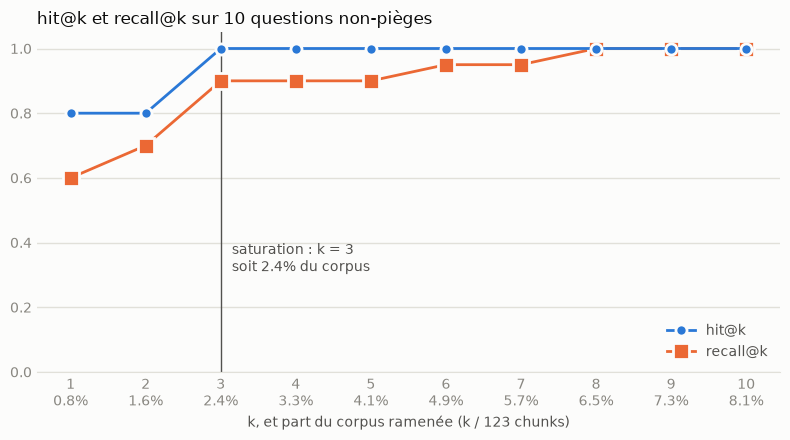

In [21]:
ks = [r["k"] for r in rows]

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
# hit@k au-dessus et en marqueurs plus petits : là où les deux courbes se confondent, on voit encore les deux
for key, label, color, marker, size, z in [("hit", "hit@k", BLUE, "o", 8, 3), ("recall", "recall@k", ORANGE, "s", 12, 2)]:
    ax.plot(ks, [r[key] for r in rows], label=label, color=color, marker=marker, zorder=z,
            linewidth=2, markersize=size, markeredgecolor=SURFACE, markeredgewidth=2)

if k_sat is not None:
    ax.axvline(k_sat, color=INK_2, linewidth=1, zorder=1)
    ax.annotate(f"saturation : k = {k_sat}\nsoit {k_sat / N_CHUNKS:.1%} du corpus",
                xy=(k_sat, 0.35), xytext=(8, 0), textcoords="offset points", color=INK_2, va="center")

# Sous chaque k, la fraction du corpus que ce k ramène : c'est ce qui relativise la saturation
ax.set_xticks(ks, [f"{k}\n{k / N_CHUNKS:.1%}" for k in ks])
ax.set_xlabel(f"k, et part du corpus ramenée (k / {N_CHUNKS} chunks)", color=INK_2)
ax.set_ylim(0, 1.05)
ax.set_title(f"hit@k et recall@k sur {len(evaluated)} questions non-pièges", color=INK, loc="left")
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(frameon=False, loc="lower right", labelcolor=INK_2)
fig.tight_layout()
plt.show()

### Réponse (a)

- **k de saturation : 3**, soit 2,4 % du corpus (3 chunks sur 123).
- hit@k passe de 0,80 à 1,00 à k = 3. Le MRR vaut 0,87 à partir de k = 3 et ne bouge plus.
- recall@k n'atteint 1,00 qu'à k = 8, à cause du second chunk gold de q03 (rang 6) et de celui de q09 (rang 8).
- Avec dix questions, hit@k avance par pas de 0,10 : la saturation à 3 tient à deux questions, q04 et q09, dont le premier chunk gold est au rang 3.
- Un k mesuré sur 123 chunks ne se transporte pas sur un corpus de 10 000.

## Étape 3 · B2 — le seuil de bruit → réponse (b)

Pour chaque question non-piège, les 10 chunks retournés sont rangés en deux sacs, gold et non-gold. On compare les deux distributions sur le score absolu, puis sur la marge au top-1 (`score_top1 - score_chunk`). La règle de coupure est fixée d'avance et identique pour les deux critères : garder environ 90 % du sac gold.

In [22]:
# Deux sacs : les K_MAX chunks retournés pour chaque question non-piège, étiquetés gold ou non-gold
scored = []
for p in evaluated:
    results = search(p["question"], k=K_MAX)
    top1 = results[0]["score"]
    for rank, c in enumerate(results, 1):
        scored.append({"rank": rank, "score": c["score"], "margin": top1 - c["score"], "gold": c["id"] in p["gold"]})

def bags(key: str) -> tuple[np.ndarray, np.ndarray]:
    """Sépare les valeurs de `key` ("score" ou "margin") en deux tableaux : (gold, non-gold)."""
    gold = np.array([s[key] for s in scored if s["gold"]])
    other = np.array([s[key] for s in scored if not s["gold"]])
    return gold, other

def make_bins(values: np.ndarray, width: float) -> np.ndarray:
    """Retourne les bornes de classes de largeur `width` qui couvrent toutes les valeurs."""
    lo = np.floor(values.min() / width) * width
    hi = np.ceil(values.max() / width) * width
    return np.linspace(lo, hi, int(round((hi - lo) / width)) + 1)

def overlap(gold: np.ndarray, other: np.ndarray, bins: np.ndarray) -> float:
    """Taux de recouvrement : aire commune aux deux histogrammes normalisés (0 = séparés, 1 = confondus)."""
    h_gold, _ = np.histogram(gold, bins)
    h_other, _ = np.histogram(other, bins)
    return float(np.minimum(h_gold / h_gold.sum(), h_other / h_other.sum()).sum())

gold_s, other_s = bags("score")
gold_m, other_m = bags("margin")
bins_s = make_bins(np.concatenate([gold_s, other_s]), 0.01)
bins_m = make_bins(np.concatenate([gold_m, other_m]), 0.005)

# Règle de coupure fixée d'avance, la même pour les deux critères : garder environ 90 % du sac gold
threshold = np.percentile(gold_s, 10)        # seuil absolu : on garde score >= threshold
max_margin = np.percentile(gold_m, 90)       # marge relative : on garde marge <= max_margin

print(f"{len(scored)} chunks : {len(gold_s)} gold, {len(other_s)} non-gold, scores entre {min(gold_s.min(), other_s.min()):.3f} et {max(gold_s.max(), other_s.max()):.3f}\n")
print(f"score  gold      min {gold_s.min():.3f}   p10 {np.percentile(gold_s, 10):.3f}   médiane {np.median(gold_s):.3f}")
print(f"       non-gold  max {other_s.max():.3f}   p90 {np.percentile(other_s, 90):.3f}   médiane {np.median(other_s):.3f}")
print(f"       recouvrement {overlap(gold_s, other_s, bins_s):.0%}")
print(f"marge  gold      max {gold_m.max():.3f}   p90 {np.percentile(gold_m, 90):.3f}   médiane {np.median(gold_m):.3f}")
print(f"       non-gold  min {other_m.min():.3f}   p10 {np.percentile(other_m, 10):.3f}   médiane {np.median(other_m):.3f}")
print(f"       recouvrement {overlap(gold_m, other_m, bins_m):.0%}\n")
print(f"seuil absolu   score >= {threshold:.3f} : garde {np.mean(gold_s >= threshold):.0%} du gold, laisse passer {np.mean(other_s >= threshold):.0%} du non-gold")
print(f"               (propre à {MODEL_NAME} et à ce corpus de {N_CHUNKS} chunks)")
print(f"marge relative marge <= {max_margin:.3f} : garde {np.mean(gold_m <= max_margin):.0%} du gold, laisse passer {np.mean(other_m <= max_margin):.0%} du non-gold\n")

# Les top-1 ont une marge nulle par construction : la séparation tient-elle sans eux ?
rest_gold = [s for s in scored if s["gold"] and s["rank"] > 1]
rest_other = [s for s in scored if not s["gold"] and s["rank"] > 1]
print(f"sans les top-1 ({len(rest_gold)} gold, {len(rest_other)} non-gold)")
print(f"  seuil absolu   : garde {sum(s['score'] >= threshold for s in rest_gold)}/{len(rest_gold)} gold, laisse passer {np.mean([s['score'] >= threshold for s in rest_other]):.0%} du non-gold")
print(f"  marge relative : garde {sum(s['margin'] <= max_margin for s in rest_gold)}/{len(rest_gold)} gold, laisse passer {np.mean([s['margin'] <= max_margin for s in rest_other]):.0%} du non-gold")

100 chunks : 15 gold, 85 non-gold, scores entre 0.801 et 0.894

score  gold      min 0.840   p10 0.843   médiane 0.870
       non-gold  max 0.893   p90 0.870   médiane 0.845
       recouvrement 54%
marge  gold      max 0.022   p90 0.012   médiane 0.000
       non-gold  min 0.000   p10 0.010   médiane 0.021
       recouvrement 31%

seuil absolu   score >= 0.843 : garde 87% du gold, laisse passer 59% du non-gold
               (propre à intfloat/multilingual-e5-base et à ce corpus de 123 chunks)
marge relative marge <= 0.012 : garde 87% du gold, laisse passer 18% du non-gold

sans les top-1 (7 gold, 83 non-gold)
  seuil absolu   : garde 6/7 gold, laisse passer 58% du non-gold
  marge relative : garde 5/7 gold, laisse passer 16% du non-gold


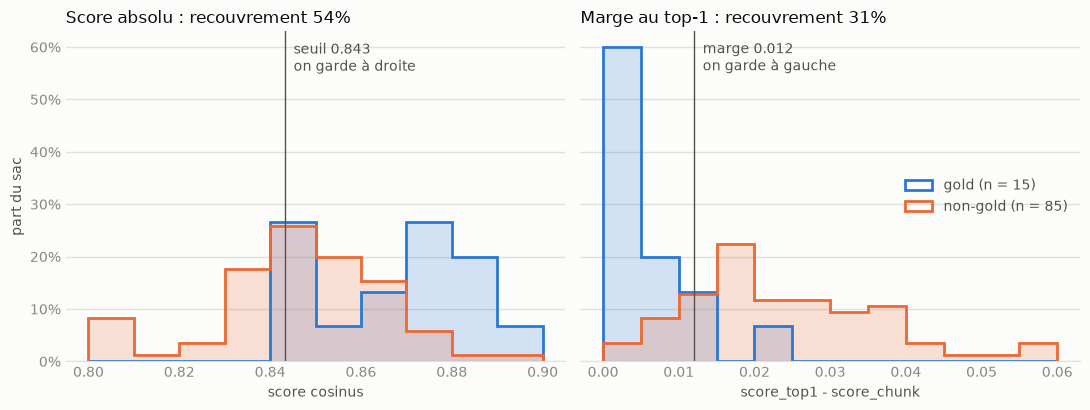

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, facecolor=SURFACE)
panels = [
    (axes[0], gold_s, other_s, bins_s, threshold, "Score absolu", f"seuil {threshold:.3f}\non garde à droite"),
    (axes[1], gold_m, other_m, bins_m, max_margin, "Marge au top-1", f"marge {max_margin:.3f}\non garde à gauche"),
]
for ax, gold, other, bins, cut, title, note in panels:
    ax.set_facecolor(SURFACE)
    for values, label, color in [(gold, f"gold (n = {len(gold)})", BLUE), (other, f"non-gold (n = {len(other)})", ORANGE)]:
        weights = np.full(len(values), 1 / len(values))      # chaque sac ramené à 100 % pour comparer 15 gold à 85 non-gold
        ax.hist(values, bins=bins, weights=weights, histtype="stepfilled", color=color, alpha=0.2)
        ax.hist(values, bins=bins, weights=weights, histtype="step", color=color, linewidth=2, label=label)
    ax.axvline(cut, color=INK_2, linewidth=1)
    ax.annotate(note, xy=(cut, 0.97), xycoords=("data", "axes fraction"), xytext=(6, 0), textcoords="offset points",
                color=INK_2, va="top")
    ax.set_title(f"{title} : recouvrement {overlap(gold, other, bins):.0%}", color=INK, loc="left")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
axes[0].set_xlabel("score cosinus", color=INK_2)
axes[1].set_xlabel("score_top1 - score_chunk", color=INK_2)
axes[0].set_ylabel("part du sac", color=INK_2)
axes[1].legend(frameon=False, loc="center right", labelcolor=INK_2)
fig.tight_layout()
plt.show()

### Réponse (b)

- **Seuil absolu : score ≥ 0,843.** Il garde 87 % du gold (13 chunks sur 15) et laisse passer 59 % du non-gold. Ce chiffre ne vaut que pour `intfloat/multilingual-e5-base` sur ce corpus de 123 chunks.
- **Marge relative : au plus 0,012 du top-1.** Elle garde les mêmes 87 % du gold et laisse passer 18 % du non-gold.
- **La marge sépare mieux** : 31 % de recouvrement contre 54 % pour le score absolu, et environ trois fois moins de bruit à rétention de gold égale.
- Tous les scores tiennent entre 0,801 et 0,894. C'est le comportement documenté d'E5 (scores concentrés entre 0,7 et 1,0, conséquence de la température 0,01 de la perte InfoNCE) : seul l'ordre relatif compte.
- Réserve : 8 des 15 chunks gold sont le top-1 de leur question, donc leur marge vaut zéro par construction. Sans les top-1, la marge garde 5 chunks gold sur 7 et laisse passer 16 % du non-gold, contre 6 sur 7 et 58 % pour le seuil absolu.

## Étape 4 · B3 — sensibilité à la formulation

Quatre questions répondables, trois formulations chacune : la naturelle (celle de `PROBES`), une version mots-clés et une version jargon juridique. On compte les requêtes dont le top-1 est gold, et les questions dont le top-1 change selon la formulation.

In [24]:
REFORMULATIONS = {
    "q03": {"mots-clés": "frais retour rétractation qui paie",
            "jargon": "Imputation des frais directs de renvoi du bien après exercice du droit de rétractation"},
    "q04": {"mots-clés": "délai maximum livraison aucune date indiquée",
            "jargon": "Délai supplétif de délivrance du bien à défaut de date convenue au contrat"},
    "q07": {"mots-clés": "téléphone reconditionné défaut présomption durée",
            "jargon": "Durée de la présomption d'antériorité du défaut de conformité pour un bien d'occasion"},
    "q08": {"mots-clés": "avance commande annulation somme perdue",
            "jargon": "Faculté de dédit et sort des arrhes en cas de renonciation du consommateur"},
}

trials = []
for probe_id, variants in REFORMULATIONS.items():
    probe = probes_by_id[probe_id]
    for style, query in {"naturelle": probe["question"], **variants}.items():
        results = search(query, k=K_MAX)
        gold_ranks = [rank for rank, c in enumerate(results, 1) if c["id"] in probe["gold"]]
        trials.append({
            "probe": probe_id, "style": style, "query": query,
            "top1": results[0],
            "top1_gold": results[0]["id"] in probe["gold"],
            "first_gold_rank": gold_ranks[0] if gold_ranks else None,     # None : aucun chunk gold dans le top-K_MAX
        })

print("question  formulation  top-1 gold  rang 1er gold  score   top-1                                           requête")
for t in trials:
    top1 = f"{t['top1']['source']} #{t['top1']['chunk_index']}"
    print(f"{t['probe']:<9} {t['style']:<12} {'oui' if t['top1_gold'] else 'NON':<11} {str(t['first_gold_rank'] or '-'):<14} {t['top1']['score']:.3f}   {top1:<47} {t['query']}")

# Deux chiffres : top-1 gold sur les 12 requêtes, et questions dont le top-1 change selon la formulation
n_gold = sum(t["top1_gold"] for t in trials)
changed, flipped = [], []
for probe_id in REFORMULATIONS:
    mine = [t for t in trials if t["probe"] == probe_id]
    if len({t["top1"]["id"] for t in mine}) > 1:
        changed.append(probe_id)                     # au moins deux top-1 différents parmi les trois formulations
    if len({t["top1_gold"] for t in mine}) > 1:
        flipped.append(probe_id)                     # le top-1 est gold avec une formulation et pas avec une autre

print(f"\ntop-1 gold : {n_gold}/{len(trials)} requêtes")
print(f"top-1 différent selon la formulation : {len(changed)}/{len(REFORMULATIONS)} questions {changed}")
print(f"dont bascule gold / non-gold : {len(flipped)}/{len(REFORMULATIONS)} questions {flipped}")
for style in ("naturelle", "mots-clés", "jargon"):
    print(f"  {style:<10} : top-1 gold sur {sum(t['top1_gold'] for t in trials if t['style'] == style)}/{len(REFORMULATIONS)} questions")
if k_sat is not None:
    in_top_k = sum(t["first_gold_rank"] is not None and t["first_gold_rank"] <= k_sat for t in trials)
    print(f"gold dans le top-{k_sat} (k de saturation) : {in_top_k}/{len(trials)} requêtes")

question  formulation  top-1 gold  rang 1er gold  score   top-1                                           requête
q03       naturelle    oui         1              0.870   retours-et-remboursements.md #0                 Qui paie les frais de retour quand on se rétracte d'un achat à distance ?
q03       mots-clés    oui         1              0.880   retours-et-remboursements.md #0                 frais retour rétractation qui paie
q03       jargon       oui         1              0.871   retours-et-remboursements.md #0                 Imputation des frais directs de renvoi du bien après exercice du droit de rétractation
q04       naturelle    NON         3              0.852   vente-a-distance-retractation.md #2             Le vendeur ne m'a indiqué aucune date de livraison : de combien de temps dispose-t-il au maximum pour me livrer ?
q04       mots-clés    oui         1              0.849   livraison-et-delais.txt #0                      délai maximum livraison aucune date indiquée
q

### Résultat

- **Le top-1 est gold sur 9 des 12 requêtes.**
- **Le top-1 change selon la formulation pour 2 questions sur 4** (q04 et q08), et dans les deux cas il bascule entre gold et non-gold : reformuler a un levier réel au rang 1.
- Par formulation : mots-clés 4 sur 4, naturelle 3 sur 4, jargon 2 sur 4. Réécrire en jargon n'est pas une direction sûre : sur q08, le gold tombe du rang 1 au rang 6.
- Au k de saturation (k = 3), 11 requêtes sur 12 ont déjà un chunk gold dans le top-3 : le levier est bien plus faible si `retrieve` ramène trois chunks.
- Les formulations ont été écrites avant la mesure et n'ont pas été retouchées. q04 est incluse exprès : c'est la seule répondable dont la question naturelle rate le rang 1.

## Étape 5 · B4 — le filtre métadonnées comme borne oracle

D'abord la plomberie : le filtre `where` ne doit ramener que des chunks du fichier demandé. Ensuite, pour chaque question dont le top-1 n'était pas gold en B1, on relance la recherche en filtrant sur le bon document. Si le chunk gold passe en tête, l'échec était un problème de classement ; sinon, un problème de représentation.

In [25]:
# Plomberie : avec where, une question sur les avions ne doit ramener que des chunks du fichier demandé
filtered = search("Mon avion est arrivé avec quatre heures de retard : à quelle indemnisation ai-je droit ?", k=3, where={"source": "garanties-legales.md"})
assert len(filtered) == 3 and {c["source"] for c in filtered} == {"garanties-legales.md"}
print("filtre where OK :", [f"{c['source']} #{c['chunk_index']}" for c in filtered])

# Borne oracle : pour chaque question dont le top-1 n'est pas gold, on relance en filtrant sur le bon document.
# Gold en tête dans son document -> problème de classement ; sinon -> problème de représentation.
for p in evaluated:
    if ranked[p["id"]][0] in p["gold"]:
        continue                                             # top-1 gold en B1 : rien à diagnostiquer
    print(f"\n{p['id']} — {p['question']}")
    gold = collection.get(ids=p["gold"], include=["metadatas"])
    for gold_id, meta in zip(gold["ids"], gold["metadatas"]):
        in_doc = search(p["question"], k=K_MAX, where={"source": meta["source"]})
        rank_all = ranked[p["id"]].index(gold_id) + 1 if gold_id in ranked[p["id"]] else None
        rank_doc = [c["id"] for c in in_doc].index(gold_id) + 1
        diagnosis = "classement" if rank_doc == 1 else "représentation"
        print(f"  gold {meta['source']} #{meta['chunk_index']} : rang {rank_all} sans filtre, rang {rank_doc}/{len(in_doc)} dans son document -> {diagnosis}")
        for c in in_doc[:rank_doc - 1]:
            print(f"    devancé dans son document par #{c['chunk_index']} ({c['score']:.3f})")

# q09 pose deux questions en une : chaque moitié, posée seule, retrouve-t-elle son chunk gold ?
Q09_PARTS = {
    "53353883912af98b": "Un article acheté en soldes avec la mention « ni repris ni échangé » tombe en panne : le vendeur peut-il refuser de le reprendre ?",
    "2ab7c37f8c4b4e5b": "Combien de temps après l'achat la garantie de conformité me couvre-t-elle ?",
}
print("\nq09, une moitié à la fois (sans filtre)")
for gold_id, part in Q09_PARTS.items():
    ids = [c["id"] for c in search(part, k=K_MAX)]
    print(f"  rang {ids.index(gold_id) + 1 if gold_id in ids else None} — {part}")

filtre where OK : ['garanties-legales.md #2', 'garanties-legales.md #3', 'garanties-legales.md #1']

q04 — Le vendeur ne m'a indiqué aucune date de livraison : de combien de temps dispose-t-il au maximum pour me livrer ?
  gold livraison-et-delais.txt #0 : rang 3 sans filtre, rang 1/3 dans son document -> classement

q09 — Un article acheté en soldes avec la mention « ni repris ni échangé » tombe en panne au bout de six mois : le vendeur peut-il refuser de le reprendre, et combien de temps après l'achat la garantie de conformité me couvre-t-elle ?
  gold garanties-legales.md #0 : rang 8 sans filtre, rang 3/4 dans son document -> représentation
    devancé dans son document par #2 (0.877)
    devancé dans son document par #1 (0.874)
  gold soldes-et-reductions-de-prix.txt #3 : rang 3 sans filtre, rang 1/6 dans son document -> classement

q09, une moitié à la fois (sans filtre)
  rang 1 — Un article acheté en soldes avec la mention « ni repris ni échangé » tombe en panne : le vendeur peu

### Diagnostic des questions dont le top-1 n'est pas gold

- **q04 : problème de classement.** Filtré sur `livraison-et-delais.txt`, le chunk gold (#0) sort en rang 1. Sans filtre il est rang 3, derrière `vente-a-distance-retractation.md` #2 et `reparation-et-durabilite.md` #1, deux chunks qui parlent eux aussi de délais. Correction attendue : un reranker.
- **q09, moitié soldes : problème de classement.** `soldes-et-reductions-de-prix.txt` #3 sort en rang 1 dans son document, rang 3 sans filtre.
- **q09, moitié garanties : la question, pas le chunk.** `garanties-legales.md` #0 reste rang 3 sur 4 même filtré sur son document. Mais posée seule, la sous-question sur la durée de la garantie le remonte au rang 2 sans filtre. Le chunk est donc bien représenté : c'est la question double qui est mal résumée par un seul vecteur. Correction attendue : décomposer la question, pas re-chunker ni changer de modèle.

Réserve : les documents filtrés comptent 3 à 6 chunks, donc « rang 1 dans son document » est un test peu exigeant.

## Étape 6 · B5 — les deux pièges → réponse (c)

Le top-5 complet des deux pièges, puis la question décisive : existe-t-il un seuil sur le score du top-1 qui rejette les deux pièges sans rejeter aucune des huit questions répondables ?

In [26]:
# Top-5 complet des deux pièges
for p in traps:
    print(f"{p['id']} — {p['question']}")
    for rank, c in enumerate(search(p["question"], k=5), 1):
        print(f"  [{rank}] {c['score']:.3f}  {c['source']} #{c['chunk_index']}\n      {c['text'][:200]}")
    print()

# Le calcul décisif : existe-t-il un seuil sur le score du top-1 qui rejette les deux pièges sans rejeter aucune répondable ?
kinds = {p["id"]: p["kind"] for p in PROBES if p["kind"] in ("answerable", "trap")}
top1_scores = {probe_id: search(probes_by_id[probe_id]["question"], k=1)[0]["score"] for probe_id in kinds}
for probe_id, score in sorted(top1_scores.items(), key=lambda item: item[1], reverse=True):
    print(f"  {score:.3f}  {probe_id}  {'PIÈGE' if kinds[probe_id] == 'trap' else 'répondable'}")

highest_trap = max(score for probe_id, score in top1_scores.items() if kinds[probe_id] == "trap")
answerable = [score for probe_id, score in top1_scores.items() if kinds[probe_id] == "answerable"]
rejected = sum(score <= highest_trap for score in answerable)      # répondables sacrifiées par un seuil qui écarte les deux pièges
verdict = "existe" if rejected == 0 else "n'existe pas"
print(f"\npiège le mieux noté : {highest_trap:.3f} | répondable la moins bien notée : {min(answerable):.3f}")
print(f"seuil séparateur : {verdict} (écarter les deux pièges rejette {rejected}/{len(answerable)} questions répondables)\n")

# Les deux coupures de B2 appliquées aux pièges : rien ne devrait survivre
for p in traps:
    scores = np.array([c["score"] for c in search(p["question"], k=K_MAX)])
    print(f"piège {p['id']} : {np.sum(scores >= threshold)}/{K_MAX} chunks passent le seuil absolu, {np.sum(scores[0] - scores <= max_margin)}/{K_MAX} passent la marge")

q11 — Quel est le délai de rétractation après la signature d'un compromis de vente pour un appartement ?
  [1] 0.867  vente-a-distance-retractation.md #1
      du droit de rétractation Le consommateur qui achète un bien ou souscrit un service à distance dispose d'un **délai de quatorze jours** pour exercer son droit de rétractation. Pendant ce délai, il peut
  [2] 0.860  credit-a-la-consommation.md #4
      emprunteur peut se rétracter, sans motif, dans un délai de **quatorze jours calendaires** à compter du jour de l'acceptation de l'offre de contrat. Un formulaire détachable est joint au contrat pour f
  [3] 0.858  vente-a-distance-retractation.md #3
      exercice du droit de rétractation, avant la conclusion du contrat. **Si le professionnel omet cette information**, le délai de rétractation est prolongé : le consommateur dispose alors d'un délai éten
  [4] 0.857  demarchage-et-vente-hors-etablissement.txt #7
      peut obtenir la restitution des sommes versees. L'age, l'etat de sa

### Pourquoi chaque chunk ramené est plausible mais ne répond pas

**q11 — délai de rétractation après un compromis de vente** (l'immobilier est absent du corpus)

1. `vente-a-distance-retractation.md` #1 (0,867) : donne « quatorze jours » pour se rétracter sans motif, exactement la forme de réponse attendue, mais pour un achat à distance auprès d'un professionnel.
2. `credit-a-la-consommation.md` #4 (0,860) : « quatorze jours calendaires » de rétractation, mais c'est l'emprunteur qui renonce à un crédit à la consommation.
3. `vente-a-distance-retractation.md` #3 (0,858) : délai prolongé de douze mois quand le professionnel n'a pas informé, et façon de se rétracter ; toujours la vente à distance.
4. `demarchage-et-vente-hors-etablissement.txt` #7 (0,857) : comment revenir sur un contrat signé lors d'un démarchage (formulaire, lettre recommandée) ; une procédure, sans délai ni immobilier.
5. `vente-a-distance-retractation.md` #2 (0,856) : point de départ du délai (réception du bien, conclusion du contrat) ; la mécanique d'un délai qui ne s'applique pas à un compromis.

Un générateur naïf répondrait « quatorze jours » en citant le chunk 1, alors que le délai légal pour un compromis est de dix jours.

**q12 — congés payés acquis par mois** (droit du travail, hors domaine)

1. `vente-a-distance-retractation.md` #2 (0,817) : parle de samedi, dimanche, jour férié et jour ouvrable ; du vocabulaire de calendrier, appliqué au délai de rétractation.
2. `vente-a-distance-retractation.md` #3 (0,816) : « douze mois », « quatorze jours » ; des durées, celles d'un délai de rétractation prolongé.
3. `abonnements-et-resiliation.md` #11 (0,815) : un reste de chunk de 57 caractères (« obligation de paiement. À défaut, le contrat est nul. ») ; aucun rapport, il remonte probablement parce qu'il est presque vide.
4. `donnees-personnelles-et-prospection.md` #6 (0,815) : « six mois », « soixante-douze heures » ; encore des délais chiffrés, sur les cookies et les fuites de données.
5. `vente-a-distance-retractation.md` #1 (0,814) : « délai de quatorze jours » ; un nombre de jours, mais de rétractation.

### Réponse (c)

> Sur ce sondage, aucun seuil sur le score du top-1 ne rejette les deux pièges sans rejeter de question répondable : le piège q11 obtient 0,867, plus que deux des huit questions répondables (q04 à 0,852 et q08 à 0,847). Le filtrage par score ne peut donc pas produire l'abstention ; il faut un juge sémantique, et c'est ce qui justifie le node critique.

Les deux coupures de B2 ne font pas mieux : le seuil absolu laisse passer les dix chunks de q11, et la marge garde les dix chunks de q12.

Deux réserves :

- **n = 2.** Deux pièges, ce n'est pas une statistique, c'est une illustration. Les trois pièges supplémentaires de la semaine 7 donneront n = 5, ce qui reste modeste.
- **Le seuil `hors_corpus` de la semaine 6 est un point de départ à réviser, pas une constante.** Sur ces données, un seuil sur le top-1 entre 0,817 et 0,847 écarte le piège hors domaine (q12) sans toucher aux questions répondables, par exemple 0,83. Il laisse passer q11.